<a href="https://colab.research.google.com/github/deekshakb629-design/Miniproject1/blob/main/minorproject2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('/content/AB_NYC_2019.csv (1).zip')

print("Dataset loaded successfully!")
df.head()

Saving AB_NYC_2019.csv (1).zip to AB_NYC_2019.csv (1).zip
Dataset loaded successfully!


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [24]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
df.info()
df.describe()

Dataset shape: (48895, 16)

Column names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Data types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object
<cla

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [25]:

numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("Numerical columns:")
print(numerical_columns.tolist())

print("\nCategorical columns:")
print(categorical_columns.tolist())

Numerical columns:
['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Categorical columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


In [26]:

missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
})

print(missing_report[missing_report['Missing Values'] > 0])

                   Missing Values  Percentage
name                           16    0.032723
host_name                      21    0.042949
last_review                 10052   20.558339
reviews_per_month           10052   20.558339


In [54]:

df.loc[
    (df['number_of_reviews'] == 0) &
    (df['reviews_per_month'].isnull()),
    'reviews_per_month'
] = 0
df['reviews_per_month'] = df['reviews_per_month'].fillna(
    df['reviews_per_month'].median()
)
df.drop(
    columns=['last_review', 'id', 'name', 'host_id', 'host_name', 'neighbourhood'],
    inplace=True,
    errors='ignore'
)
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
latitude                             0
longitude                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
neighbourhood_group_Brooklyn         0
neighbourhood_group_Manhattan        0
neighbourhood_group_Queens           0
neighbourhood_group_Staten Island    0
room_type_Private room               0
room_type_Shared room                0
dtype: int64


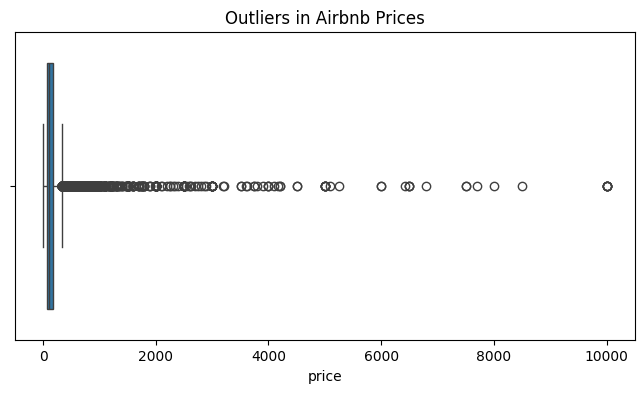

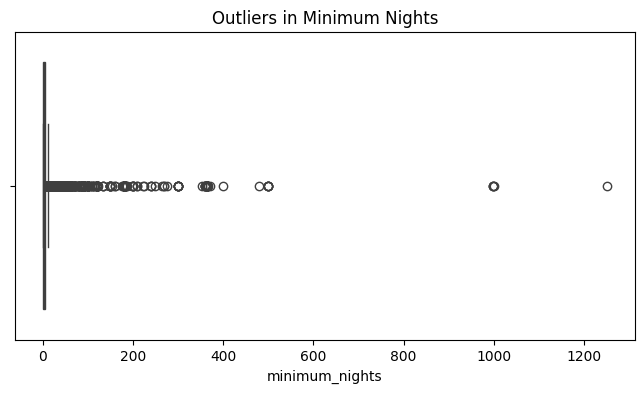

In [28]:

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['price'])
plt.title("Outliers in Airbnb Prices")
plt.show()
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['minimum_nights'])
plt.title("Outliers in Minimum Nights")
plt.show()

In [29]:
price_limit = df['price'].quantile(0.95)
nights_limit = df['minimum_nights'].quantile(0.95)

print("Price limit:", price_limit)
print("Minimum nights limit:", nights_limit)
df = df[
    (df['price'] > 0) &
    (df['price'] <= price_limit) &
    (df['minimum_nights'] <= nights_limit)
]

print("Dataset shape after removing outliers:", df.shape)

Price limit: 355.0
Minimum nights limit: 30.0
Dataset shape after removing outliers: (45748, 16)


In [30]:

df = pd.get_dummies(
    df,
    columns=['neighbourhood_group', 'room_type'],
    drop_first=True,
    dtype=int
)

print("Dataset after encoding:")
df.head()

Dataset after encoding:


,id,name,host_id,host_name,neighbourhood,latitude,longitude,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,2539,Clean & quiet apt home by the park,2787,John,Kensington,40.64749,-73.97237,149,1,9,2018-10-19,0.21,6,365,1,0,0,0,1,0
1,2595,Skylit Midtown Castle,2845,Jennifer,Midtown,40.75362,-73.98377,225,1,45,2019-05-21,0.38,2,355,0,1,0,0,0,0
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Harlem,40.80902,-73.94190,150,3,0,NaN,NaN,1,365,0,1,0,0,1,0
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Clinton Hill,40.68514,-73.95976,89,1,270,2019-07-05,4.64,1,194,1,0,0,0,0,0
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,East Harlem,40.79851,-73.94399,80,10,9,2018-11-19,0.10,1,0,0,1,0,0,0,0


In [31]:

X = df.drop('price', axis=1)

y = df['price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (45748, 19)
Target shape: (45748,)


In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (36598, 19)
Testing data: (9150, 19)


In [49]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (36598, 13)
Testing data: (9150, 13)


In [55]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
X = df.drop('price', axis=1)
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully on the cleaned dataset!")

Model trained successfully on the cleaned dataset!


In [56]:
y_pred = model.predict(X_test)
results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(results.head(10))

   Actual Price  Predicted Price
0            80       107.114432
1            73       145.833190
2           186       184.774299
3           150       166.007019
4           229       140.962172
5           180       157.897992
6           180       145.200040
7            49        72.325283
8           145       142.100589
9            54        90.995701


In [57]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("Model Performance")
print("-----------------------")
print("R2 Score:", round(r2, 4))
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))

Model Performance
-----------------------
R2 Score: 0.4868
Mean Absolute Error: 38.32
Mean Squared Error: 2760.62
Root Mean Squared Error: 52.54


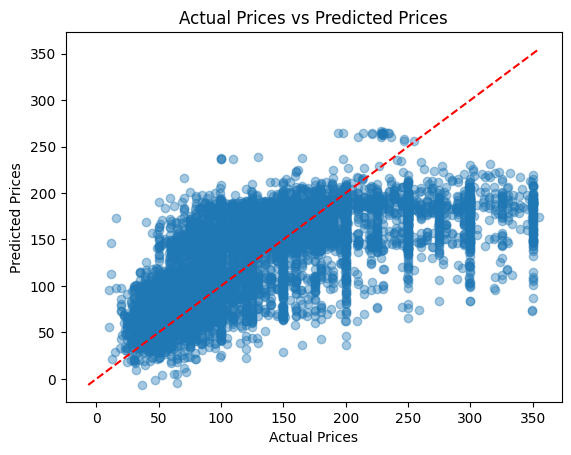

In [58]:

plt.scatter(y_test, y_pred, alpha=0.4)
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual Prices vs Predicted Prices")

plt.show()

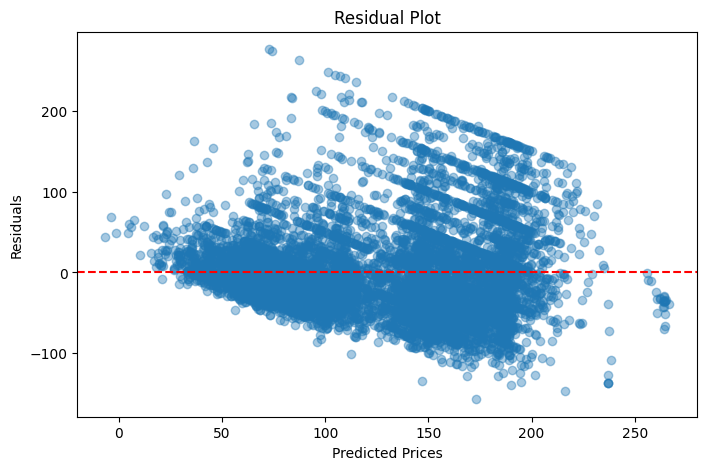

In [59]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.4)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [60]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})
comparison['Error'] = abs(
    comparison['Actual Price'] - comparison['Predicted Price']
)
price_limit = comparison['Actual Price'].median()

cheap_listings = comparison[
    comparison['Actual Price'] <= price_limit
]

expensive_listings = comparison[
    comparison['Actual Price'] > price_limit
]


cheap_error = cheap_listings['Error'].mean()
expensive_error = expensive_listings['Error'].mean()

print("Average error for cheaper listings:", round(cheap_error, 2))
print("Average error for expensive listings:", round(expensive_error, 2))

if cheap_error < expensive_error:
    print("The model performs better on cheaper listings.")
elif cheap_error > expensive_error:
    print("The model performs better on expensive listings.")
else:
    print("The model performs equally on both groups.")

Average error for cheaper listings: 29.01
Average error for expensive listings: 48.18
The model performs better on cheaper listings.
